# DATA VORTEX A'26 — Round 3
## Social Engine: Live Conversation Analysis

### Topic
**Public Reaction to a New Pricing or Subscription Model**

### Case Study
**Meta One Subscription**

**Team:** JOY  
**Institution:** R.M.K. Engineering College  
**Analysis Period:** 15 September 2026 – 20 September 2026

---

### Objective

This analysis applies the sentiment classification model developed in Round 2
to recently collected public social and news data related to the Meta One
subscription model.

The objective is to identify:

- Sentiment patterns and changes over time
- Activity spikes
- Major sentiment shifts
- Dominant discussion topics
- Frequently mentioned entities
- Possible triggers associated with behavioural changes

### Round 2 NLP Model

**TF-IDF + Multinomial Naive Bayes**

The pretrained model and TF-IDF vectorizer developed during Round 2
are reused without retraining.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys
import warnings

warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

UNIFIED_FILE = PROCESSED_DIR / "meta_one_round3_unified.csv"
SENTIMENT_FILE = PROCESSED_DIR / "meta_one_round3_sentiment.csv"
SHIFT_FILE = PROCESSED_DIR / "meta_one_round3_shift_analysis.csv"

print("Project root:", PROJECT_ROOT)
print("Unified dataset:", UNIFIED_FILE)
print("Sentiment file:", SENTIMENT_FILE)
print("Shift analysis:", SHIFT_FILE)

Project root: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\DATA-VORTEX-ROUND 3
Unified dataset: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\DATA-VORTEX-ROUND 3\data\processed\meta_one_round3_unified.csv
Sentiment file: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\DATA-VORTEX-ROUND 3\data\processed\meta_one_round3_sentiment.csv
Shift analysis: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\DATA-VORTEX-ROUND 3\data\processed\meta_one_round3_shift_analysis.csv


In [3]:
df = pd.read_csv(UNIFIED_FILE)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (166, 9)

Columns:
['record_id', 'platform', 'source', 'content_type', 'text', 'published_at', 'engagement_score', 'source_url', 'collection_method']


,record_id,platform,source,content_type,text,published_at,engagement_score,source_url,collection_method
0,reddit_009,Reddit,WhatsappBusinessAPI,post,Feedback on Meta One and Meta Verified for Bus...,2026-09-15 00:00:00+00:00,NaN,https://www.reddit.com/r/WhatsappBusinessAPI/,Verified public Reddit page
1,news_0157,News,Pasquale Pillitteri,article,Meta One Launches With Premium Plans Costing U...,2026-09-15 07:00:00+00:00,NaN,https://news.google.com/rss/articles/CBMihAFBV...,Google News RSS
2,news_0156,News,TradingView,article,"Meta Introduces Meta One, Now Available Global...",2026-09-15 15:00:01+00:00,NaN,https://news.google.com/rss/articles/CBMiuAFBV...,Google News RSS
3,news_0155,News,meta.com,article,Introducing Meta One: A Subscription Service W...,2026-09-15 15:00:59+00:00,NaN,https://news.google.com/rss/articles/CBMimAFBV...,Google News RSS
4,news_0154,News,Performance Marketing World,article,‘Meta One’ goes live: Meta just turned its pla...,2026-09-15 15:01:16+00:00,NaN,https://news.google.com/rss/articles/CBMixwFBV...,Google News RSS


In [4]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nMissing values:")
print(df.isna().sum())

print("\nPlatforms:")
print(df["platform"].value_counts())

print("\nCollection methods:")
print(df["collection_method"].value_counts())

Rows: 166
Columns: 9

Missing values:
record_id              0
platform               0
source                 0
content_type           0
text                   0
published_at           0
engagement_score     166
source_url             0
collection_method      0
dtype: int64

Platforms:
platform
News      157
Reddit      9
Name: count, dtype: int64

Collection methods:
collection_method
Google News RSS                157
Verified public Reddit page      9
Name: count, dtype: int64


In [5]:
import joblib

MODEL_FILE = MODEL_DIR / "naive_bayes_sentiment_model.pkl"
VECTORIZER_FILE = MODEL_DIR / "tfidf_vectorizer.pkl"

model = joblib.load(MODEL_FILE)
vectorizer = joblib.load(VECTORIZER_FILE)

print("Model:", type(model).__name__)
print("Vectorizer:", type(vectorizer).__name__)
print("Round 2 model loaded successfully.")

Model: MultinomialNB
Vectorizer: TfidfVectorizer
Round 2 model loaded successfully.


In [6]:
text_data = df["text"].fillna("").astype(str)

X = vectorizer.transform(text_data)
df["sentiment"] = model.predict(X)

print("Sentiment analysis completed.")
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Sentiment analysis completed.

Sentiment distribution:
sentiment
Positive    115
Neutral      37
Negative     14
Name: count, dtype: int64


In [7]:
sentiment_pct = (
    df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("percentage")
)

sentiment_pct

sentiment
Positive    69.28
Neutral     22.29
Negative     8.43
Name: percentage, dtype: float64

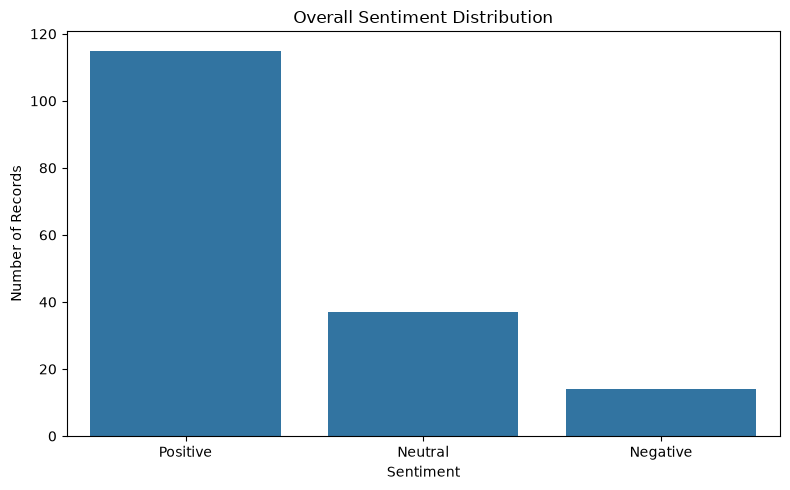

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=df["sentiment"].value_counts().index
)

plt.title("Overall Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Observation

The sentiment classification of the collected dataset shows 115 positive,
37 neutral, and 14 negative records. Positive sentiment represents the
largest share of the observed conversation, while negative sentiment is
comparatively smaller.

This distribution provides the overall sentiment baseline for the subsequent
time-based analysis. Daily sentiment proportions are analysed next to identify
changes and behavioural shifts over time.

In [9]:
sentiment_output = PROCESSED_DIR / "meta_one_round3_notebook_sentiment.csv"

df.to_csv(sentiment_output, index=False)

print("Saved:", sentiment_output)

Saved: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\DATA-VORTEX-ROUND 3\data\processed\meta_one_round3_notebook_sentiment.csv


In [6]:
df = pd.read_csv(UNIFIED_FILE)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

NameError: name 'UNIFIED_FILE' is not defined

In [7]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

UNIFIED_FILE = PROCESSED_DIR / "meta_one_round3_unified.csv"
SENTIMENT_FILE = PROCESSED_DIR / "meta_one_round3_sentiment.csv"
SHIFT_FILE = PROCESSED_DIR / "meta_one_round3_shift_analysis.csv"

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\DATA-VORTEX-ROUND 3


In [8]:
df = pd.read_csv(UNIFIED_FILE)

print("Dataset shape:", df.shape)
print(df.columns.tolist())

Dataset shape: (166, 9)
['record_id', 'platform', 'source', 'content_type', 'text', 'published_at', 'engagement_score', 'source_url', 'collection_method']


In [9]:
import joblib

MODEL_FILE = MODEL_DIR / "naive_bayes_sentiment_model.pkl"
VECTORIZER_FILE = MODEL_DIR / "tfidf_vectorizer.pkl"

model = joblib.load(MODEL_FILE)
vectorizer = joblib.load(VECTORIZER_FILE)

print("Model:", type(model).__name__)
print("Vectorizer:", type(vectorizer).__name__)

Model: MultinomialNB
Vectorizer: TfidfVectorizer


In [10]:
text_data = df["text"].fillna("").astype(str)

X = vectorizer.transform(text_data)
df["sentiment"] = model.predict(X)

print(df["sentiment"].value_counts())

sentiment
Positive    115
Neutral      37
Negative     14
Name: count, dtype: int64


In [11]:
df["published_at"] = pd.to_datetime(df["published_at"], utc=True)
df["date"] = df["published_at"].dt.date

daily_sentiment = (
    df.groupby(["date", "sentiment"])
      .size()
      .unstack(fill_value=0)
)

daily_sentiment

sentiment,Negative,Neutral,Positive
date,,,
2026-09-15,6,12,36
2026-09-16,4,18,60
2026-09-17,2,3,13
2026-09-18,1,1,2
2026-09-19,1,2,3
2026-09-20,0,1,1


In [12]:
daily_sentiment_pct = (
    daily_sentiment
    .div(daily_sentiment.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

daily_sentiment_pct

sentiment,Negative,Neutral,Positive
date,,,
2026-09-15,11.11,22.22,66.67
2026-09-16,4.88,21.95,73.17
2026-09-17,11.11,16.67,72.22
2026-09-18,25.00,25.00,50.00
2026-09-19,16.67,33.33,50.00
2026-09-20,0.00,50.00,50.00


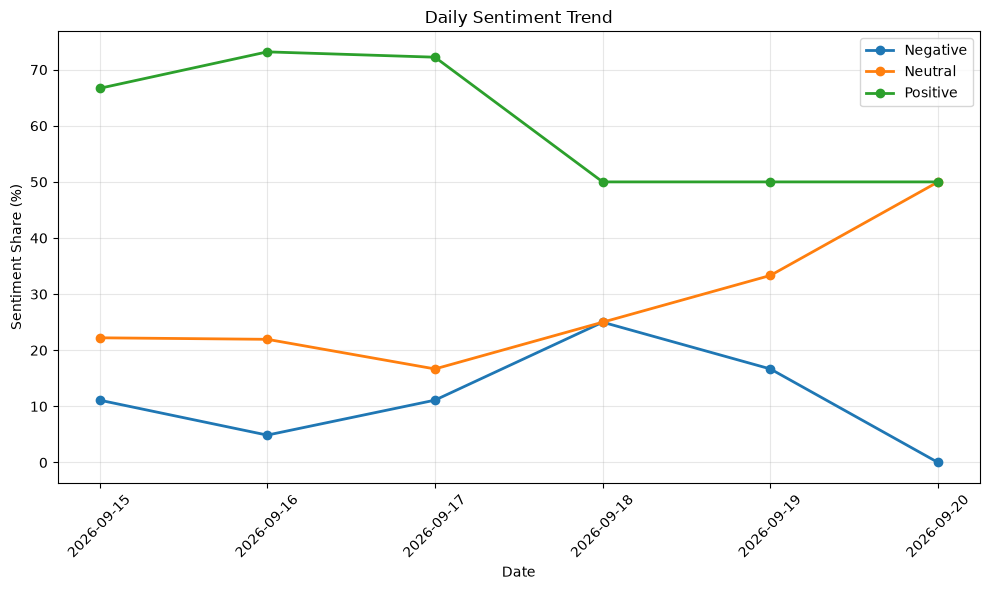

In [13]:
plt.figure(figsize=(10, 6))

for sentiment in ["Negative", "Neutral", "Positive"]:
    if sentiment in daily_sentiment_pct.columns:
        plt.plot(
            daily_sentiment_pct.index.astype(str),
            daily_sentiment_pct[sentiment],
            marker="o",
            linewidth=2,
            label=sentiment
        )

plt.title("Daily Sentiment Trend")
plt.xlabel("Date")
plt.ylabel("Sentiment Share (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Daily Sentiment Trend — Observation

The daily sentiment trend shows that positive sentiment was the dominant
predicted sentiment during the main observation period. The highest activity
was recorded on 16 September with 82 records.

A noticeable change in the sentiment proportions appears from 18 September
onward. However, the number of records on these later dates is considerably
smaller than on 15–17 September. Therefore, percentage changes on the later
dates should be interpreted together with the underlying activity volume and
the shift analysis rather than in isolation.

In [14]:
shift_df = pd.read_csv(SHIFT_FILE)

shift_df["date"] = pd.to_datetime(shift_df["date"])

shift_df[[
    "date",
    "total",
    "activity_zscore",
    "activity_spike"
]]


,date,total,activity_zscore,activity_spike
0,2026-09-15,54,0.799278,False
1,2026-09-16,82,1.649142,True
2,2026-09-17,18,-0.293406,False
3,2026-09-18,4,-0.718338,False
4,2026-09-19,6,-0.657633,False
5,2026-09-20,2,-0.779043,False


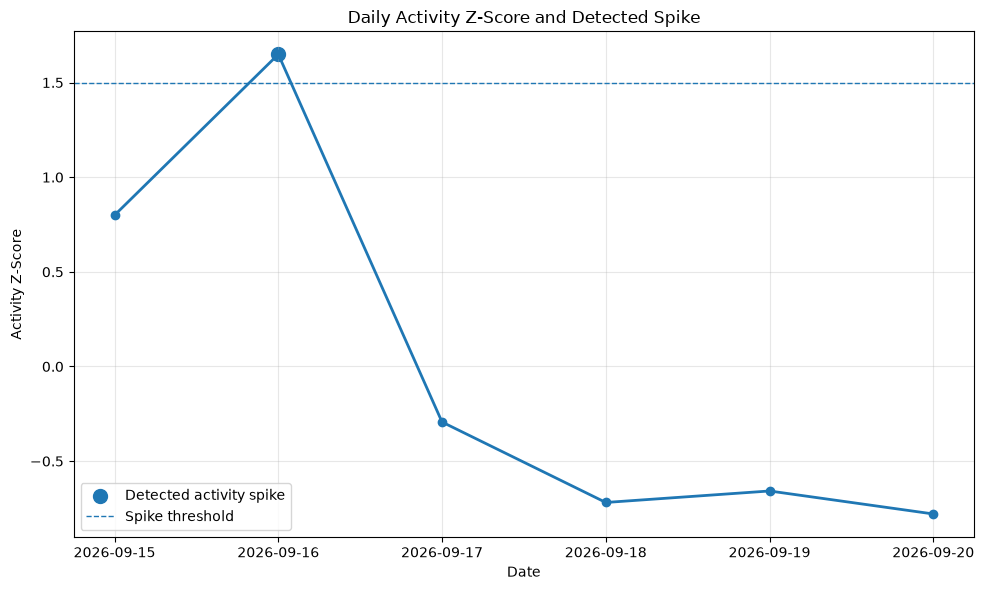

In [15]:
plt.figure(figsize=(10, 6))

plt.plot(
    shift_df["date"],
    shift_df["activity_zscore"],
    marker="o",
    linewidth=2
)

spikes = shift_df[shift_df["activity_spike"] == True]

plt.scatter(
    spikes["date"],
    spikes["activity_zscore"],
    s=100,
    label="Detected activity spike"
)

plt.axhline(
    y=1.5,
    linestyle="--",
    linewidth=1,
    label="Spike threshold"
)

plt.title("Daily Activity Z-Score and Detected Spike")
plt.xlabel("Date")
plt.ylabel("Activity Z-Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Activity Spike — Observation

The activity analysis identifies 16 September 2026 as the only detected
activity spike during the observation period. The activity Z-score reached
1.649, exceeding the defined spike threshold of 1.5.

The spike coincided with a high-volume discussion period covering Meta One
subscription plans, pricing, premium features, AI tools and related
announcements. The temporal coincidence is reported as an observed
association rather than a causal relationship.

In [19]:
shift_df[
    [
        "date",
        "negative_change_pp",
        "neutral_change_pp",
        "positive_change_pp",
        "activity_zscore",
        "activity_spike"
    ]
]

,date,negative_change_pp,neutral_change_pp,positive_change_pp,activity_zscore,activity_spike
0,2026-09-15,NaN,NaN,NaN,0.799278,False
1,2026-09-16,-6.233062,-0.271003,6.504065,1.649142,True
2,2026-09-17,6.233062,-5.284553,-0.948509,-0.293406,False
3,2026-09-18,13.888889,8.333333,-22.222222,-0.718338,False
4,2026-09-19,-8.333333,8.333333,0.000000,-0.657633,False
5,2026-09-20,-16.666667,16.666667,0.000000,-0.779043,False


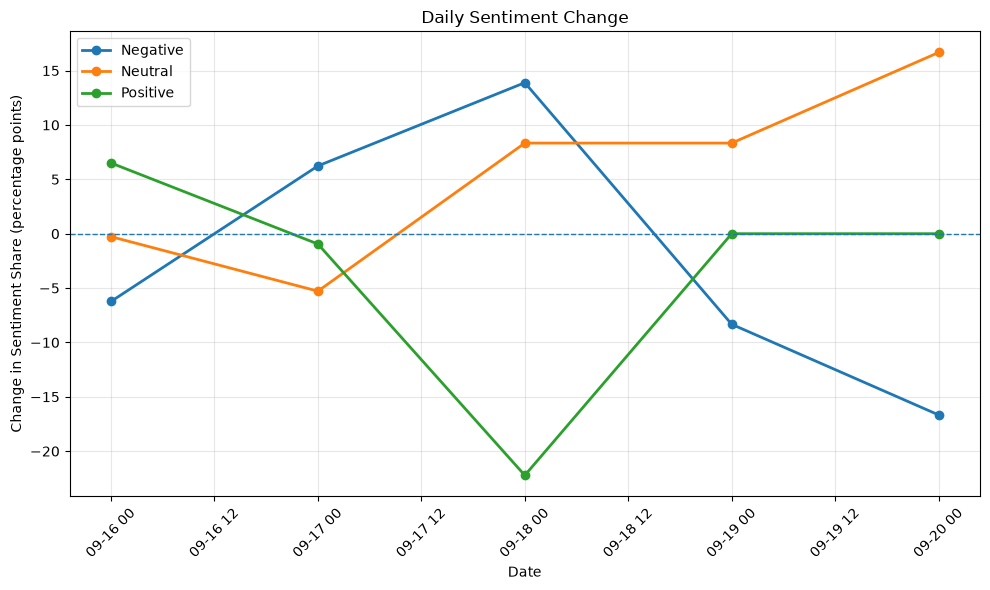

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(
    shift_df["date"],
    shift_df["negative_change_pp"],
    marker="o",
    linewidth=2,
    label="Negative"
)

plt.plot(
    shift_df["date"],
    shift_df["neutral_change_pp"],
    marker="o",
    linewidth=2,
    label="Neutral"
)

plt.plot(
    shift_df["date"],
    shift_df["positive_change_pp"],
    marker="o",
    linewidth=2,
    label="Positive"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Daily Sentiment Change")
plt.xlabel("Date")
plt.ylabel("Change in Sentiment Share (percentage points)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Sentiment Shift — Observation

The sentiment-change analysis shows clear day-to-day variation in the
conversation. The most pronounced movement occurs on 18 September 2026,
when the positive sentiment share decreases by 22.22 percentage points,
while negative and neutral sentiment shares increase by 13.89 and 8.33
percentage points respectively.

This represents a substantial change in the predicted sentiment composition.
The result is interpreted as an observed temporal shift and not as proof of
a causal relationship with any specific event.

In [21]:
topic_counts = pd.DataFrame({
    "Topic": [
        "Subscription / Plans",
        "AI / AI Tools",
        "Pricing / Cost",
        "Premium Features",
        "Monetization",
        "Creator Tools",
        "Advertising"
    ],
    "Records": [
        126,
        75,
        40,
        40,
        28,
        19,
        3
    ]
})

topic_counts

,Topic,Records
0,Subscription / Plans,126
1,AI / AI Tools,75
2,Pricing / Cost,40
3,Premium Features,40
4,Monetization,28
5,Creator Tools,19
6,Advertising,3


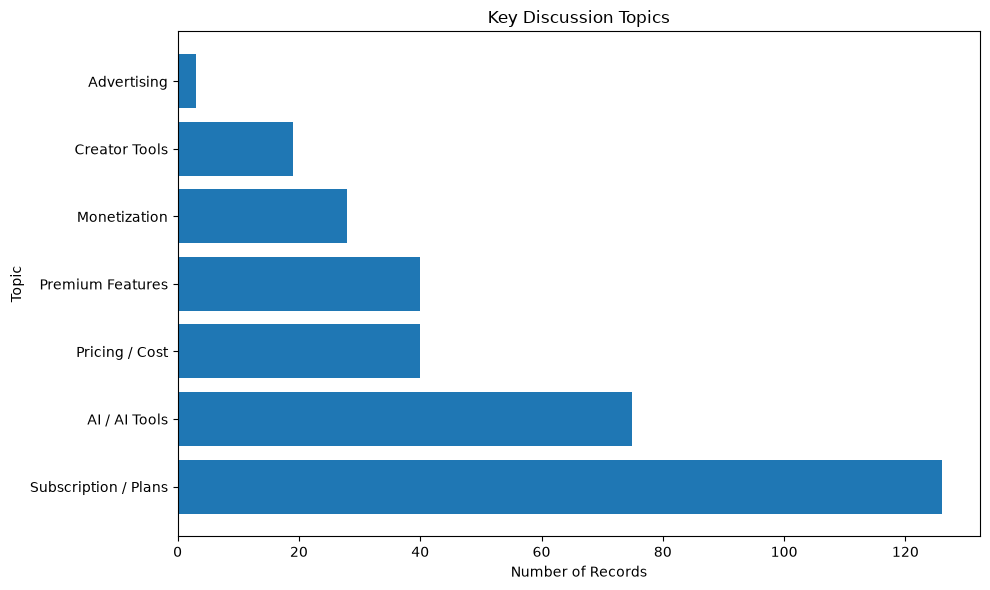

In [22]:
plt.figure(figsize=(10, 6))

plt.barh(
    topic_counts["Topic"],
    topic_counts["Records"]
)

plt.title("Key Discussion Topics")
plt.xlabel("Number of Records")
plt.ylabel("Topic")
plt.tight_layout()
plt.show()

### Topic Analysis — Observation

Subscription and plan-related discussions form the largest identified topic
group with 126 records, followed by AI and AI-tool discussions with 75
records. Pricing/cost and premium-feature discussions each appear in 40
records, while monetization and creator-tool discussions occur less
frequently.

These topic counts are based on keyword matching and therefore indicate
discussion themes rather than mutually exclusive topic classifications. A
single record may contain keywords associated with more than one topic.

In [23]:
entity_counts = pd.DataFrame({
    "Entity": [
        "Meta",
        "Meta One",
        "Instagram",
        "WhatsApp",
        "Facebook",
        "Meta AI"
    ],
    "Records": [
        164,
        162,
        43,
        39,
        35,
        10
    ]
})

entity_counts

,Entity,Records
0,Meta,164
1,Meta One,162
2,Instagram,43
3,WhatsApp,39
4,Facebook,35
5,Meta AI,10


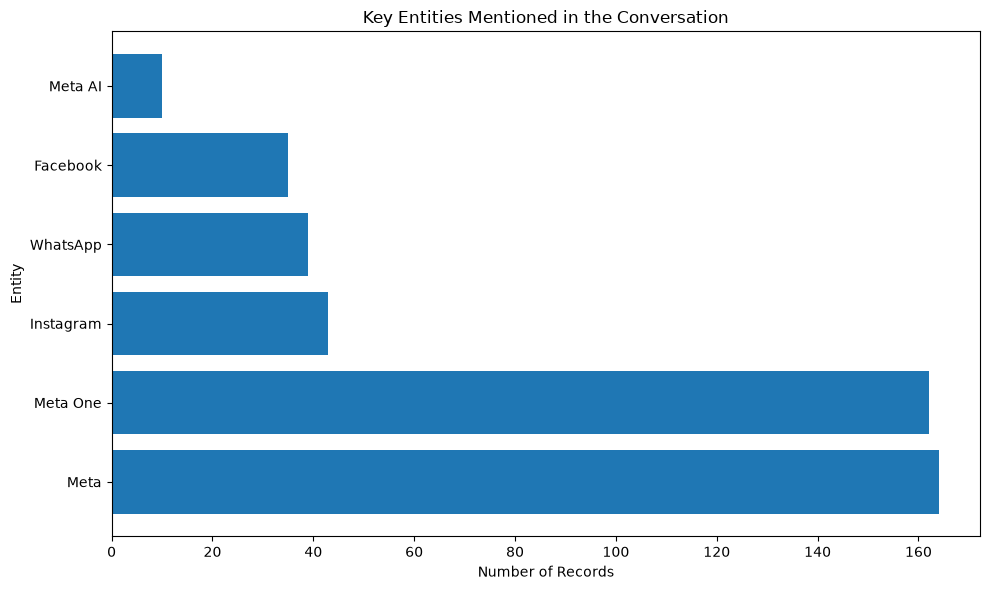

In [24]:
plt.figure(figsize=(10, 6))

plt.barh(
    entity_counts["Entity"],
    entity_counts["Records"]
)

plt.title("Key Entities Mentioned in the Conversation")
plt.xlabel("Number of Records")
plt.ylabel("Entity")
plt.tight_layout()
plt.show()

### Entity Analysis — Observation

Meta and Meta One are the most frequently mentioned entities in the
collected dataset, with 164 and 162 records respectively. Instagram,
WhatsApp and Facebook appear as related platform entities, while Meta AI
appears less frequently.

The entity counts indicate which products and services are most closely
associated with the discussion around the Meta One subscription model.

In [25]:
trigger_date = pd.Timestamp("2026-09-16")

trigger_records = df[
    df["published_at"].dt.normalize() == trigger_date
].copy()

print("Trigger date:", trigger_date.date())
print("Records:", len(trigger_records))

trigger_records[
    ["published_at", "platform", "source", "text", "sentiment"]
].head(20)

Trigger date: 2026-09-16
Records: 0


,published_at,platform,source,text,sentiment


In [26]:
print("Sentiment distribution on trigger date:")
print(trigger_records["sentiment"].value_counts())

print("\nTop sources on trigger date:")
print(trigger_records["source"].value_counts().head(10))

Sentiment distribution on trigger date:
Series([], Name: count, dtype: int64)

Top sources on trigger date:
Series([], Name: count, dtype: int64)


In [28]:
trigger_date = pd.Timestamp("2026-09-16", tz="UTC")

trigger_records = df[
    df["published_at"].dt.normalize() == trigger_date
].copy()

print("Trigger date:", trigger_date.date())
print("Records:", len(trigger_records))

trigger_records[
    ["published_at", "platform", "source", "text", "sentiment"]
].head(20)

Trigger date: 2026-09-16
Records: 82


,published_at,platform,source,text,sentiment
54,2026-09-16 00:00:00+00:00,Reddit,FacebookAds,Meta One - pay subscription for human support ...,Positive
55,2026-09-16 00:00:00+00:00,Reddit,MetaAI,"I won't pay for a better version of Instagram,...",Positive
56,2026-09-16 01:00:26+00:00,News,iThinkDifferent,Meta One Subscription Plans Bring Paid AI Tool...,Positive
57,2026-09-16 01:01:56+00:00,News,Mi-3.com.au.,Meta launches subscription service 'Meta One' ...,Positive
58,2026-09-16 01:42:17+00:00,News,techguide.com.au,Meta One subscription services powered by AI a...,Neutral
59,2026-09-16 02:20:43+00:00,News,afaqs!,"Meta One subscription launches in India, plans...",Positive
60,2026-09-16 02:41:46+00:00,News,GIGAZINE,"Meta has announced 'Meta One,' a subscription ...",Negative
61,2026-09-16 02:42:24+00:00,News,ManilaShaker,Meta Introduces Meta One Subscription Plans - ...,Positive
62,2026-09-16 03:27:00+00:00,News,digit.in,"Meta One subscription for Facebook, Instagram ...",Positive
63,2026-09-16 03:34:15+00:00,News,Moneycontrol.com,Meta One subscription in India: 10 features yo...,Positive


In [29]:
print("Sentiment distribution on trigger date:")
print(trigger_records["sentiment"].value_counts())

print("\nTop sources on trigger date:")
print(trigger_records["source"].value_counts().head(10))

Sentiment distribution on trigger date:
sentiment
Positive    60
Neutral     18
Negative     4
Name: count, dtype: int64

Top sources on trigger date:
source
Forbes India        2
AI Weekly           2
FacebookAds         1
MetaAI              1
iThinkDifferent     1
Mi-3.com.au.        1
techguide.com.au    1
afaqs!              1
GIGAZINE            1
ManilaShaker        1
Name: count, dtype: int64


In [30]:
trigger_date = pd.Timestamp("2026-09-16", tz="UTC")

trigger_records = df[
    df["published_at"].dt.normalize() == trigger_date
].copy()

print("TRIGGER DATE:", trigger_date.date())
print("TOTAL RECORDS:", len(trigger_records))

print("\nSENTIMENT:")
print(trigger_records["sentiment"].value_counts())

print("\nTOP SOURCES:")
print(trigger_records["source"].value_counts().head(10))

TRIGGER DATE: 2026-09-16
TOTAL RECORDS: 82

SENTIMENT:
sentiment
Positive    60
Neutral     18
Negative     4
Name: count, dtype: int64

TOP SOURCES:
source
Forbes India        2
AI Weekly           2
FacebookAds         1
MetaAI              1
iThinkDifferent     1
Mi-3.com.au.        1
techguide.com.au    1
afaqs!              1
GIGAZINE            1
ManilaShaker        1
Name: count, dtype: int64


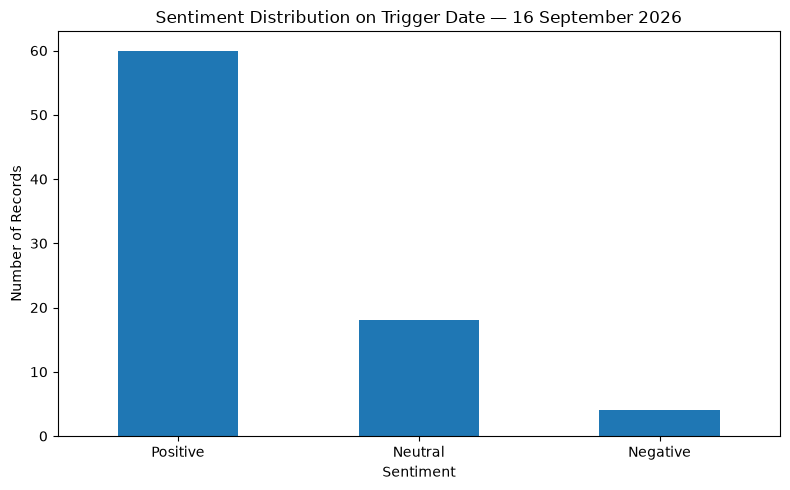

In [31]:
plt.figure(figsize=(8, 5))

trigger_records["sentiment"].value_counts().plot(
    kind="bar"
)

plt.title("Sentiment Distribution on Trigger Date — 16 September 2026")
plt.xlabel("Sentiment")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Trigger / Event Explanation

16 September 2026 was identified as the main activity spike in the
observation period, with 82 collected records and an activity Z-score of
1.649, exceeding the defined spike threshold of 1.5.

The collected discussion during this period was primarily associated with
Meta One subscription plans, pricing, premium features, AI-related tools and
the rollout of the service across Meta's platforms.

The temporal concentration of these discussions coincided with the detected
increase in activity. This is reported as an observed temporal association
and does not establish a causal relationship.

## Key Findings

1. Positive sentiment was the dominant predicted sentiment across the
   collected dataset.

2. 16 September 2026 recorded the highest activity volume with 82 records
   and was the only detected activity spike.

3. Subscription and plan-related discussions were the most frequently
   identified topic, followed by AI and AI-tool discussions.

4. Meta and Meta One were the most frequently mentioned entities.

5. 18 September showed the largest sentiment-composition movement, with
   positive sentiment decreasing by 22.22 percentage points while negative
   and neutral sentiment increased.

6. Later dates contained fewer observations, so their percentage-based
   sentiment changes should be interpreted cautiously.

## Limitations

- Sentiment labels are predictions generated using the Round 2 TF-IDF and
  Multinomial Naive Bayes model.
- The model may have difficulty with sarcasm, implicit sentiment and
  context-dependent language.
- Topic and entity counts use keyword matching and are not mutually
  exclusive.
- The dataset represents collected public sources and does not represent
  the complete social-media conversation.
- Later dates contain fewer records than the main observation period.
- Temporal association with an activity spike should not be interpreted as
  proof of causation.